# 02 · Clasificador de titulares

**Pregunta:** ¿Puede un modelo pequeño aprender a clasificar un titular peruano en política, economía, deportes o ciencia/tecnología?

Etapa 2 (issue #2): etiquetar con un LLM y medir cuánto confiar en él.
Etapa 3 (issue #3): zero-shot, fine-tuning y evaluación. Las métricas se calculan **solo** con el conjunto de prueba.

In [1]:
import time
import unicodedata
from pathlib import Path

import pandas as pd
import anthropic
from dotenv import load_dotenv

# La clave vive en tarea_1/.env, nunca escrita en el notebook
load_dotenv()

True

## 1. Cargar los titulares

Los de `datos/noticias.csv`, recolectados en el notebook 01.

In [2]:
noticias = pd.read_csv("datos/noticias.csv")
noticias["bajada"] = noticias["bajada"].fillna("")
noticias.shape

(562, 7)

In [3]:
noticias["etiqueta"].value_counts()

etiqueta
deportes              182
economia              155
politica              142
ciencia_tecnologia     83
Name: count, dtype: int64

## 2. El prompt

El LLM recibe el titular y la bajada, y debe responder **una sola palabra** de una lista cerrada.
Como la respuesta puede variar un poco entre corridas, guardamos las etiquetas en un archivo y no las volvemos a pedir.

In [4]:
categorias_validas = ["politica", "economia", "deportes", "ciencia_tecnologia"]

instrucciones = (
    "Eres un editor de un diario peruano. Clasifica cada noticia en UNA de estas categorias:\n"
    "- politica: gobierno, Congreso, partidos, elecciones, justicia y autoridades\n"
    "- economia: precios, empleo, empresas, finanzas, comercio, dolar, inflacion\n"
    "- deportes: futbol y cualquier otro deporte, torneos, deportistas\n"
    "- ciencia_tecnologia: ciencia, tecnologia, salud, medio ambiente, innovacion\n"
    "- otra: si no encaja con claridad en ninguna de las cuatro\n"
    "Responde solo con la palabra de la categoria, sin tildes, sin explicacion."
)

cliente = anthropic.Anthropic()

In [5]:
respuesta = cliente.messages.create(
    model="claude-haiku-5-5",
    max_tokens=300,
    system=instrucciones,
    messages=[{"role": "user", "content": "Titular: Congreso aprueba nueva ley de pensiones"}],
)

# La respuesta es una lista de bloques; algunos son razonamiento. Buscamos el de texto.
for bloque in respuesta.content:
    print(bloque.type)

text


In [6]:
for bloque in respuesta.content:
    if bloque.type == "text":
        print(bloque.text)

politica


## 3. Clasificar un titular, y limpiar la respuesta

El modelo puede devolver `Política` con tilde y mayúscula. Antes de comparar normalizamos, y lo que no esté en la lista queda como `sin_clasificar`.

In [7]:
def normalizar(texto):
    # NFD separa la letra de su tilde; quitamos las marcas y dejamos la letra base
    separado = unicodedata.normalize("NFD", texto.lower().strip())
    return "".join(letra for letra in separado if unicodedata.category(letra) != "Mn")

In [8]:
normalizar("Política"), normalizar("  Ciencia_Tecnología ")

('politica', 'ciencia_tecnologia')

In [9]:
# Esta función se llama una vez por titular (cientos de veces), así que ahora sí conviene
def clasificar_titular(titular, bajada):
    texto = "Titular: " + titular + "\nBajada: " + bajada

    for intento in range(2):
        try:
            respuesta = cliente.messages.create(
                model="claude-haiku-5-5",
                max_tokens=300,
                system=instrucciones,
                messages=[{"role": "user", "content": texto}],
            )
            texto_respuesta = ""
            for bloque in respuesta.content:
                if bloque.type == "text":
                    texto_respuesta = bloque.text
            etiqueta = normalizar(texto_respuesta)
            if etiqueta in categorias_validas:
                return etiqueta
            return "otra"
        except anthropic.APIError:
            time.sleep(2)

    return "sin_clasificar"

In [10]:
clasificar_titular(noticias.loc[0, "titular"], noticias.loc[0, "bajada"])

'economia'

## 4. Etiquetar todos los titulares

Guardamos en `datos/etiquetas_llm.csv`. Si ya hay etiquetas de corridas anteriores, **no se repiten**: solo se paga por las notas nuevas.

In [11]:
ruta_etiquetas = Path("datos/etiquetas_llm.csv")

if ruta_etiquetas.exists():
    etiquetas_previas = pd.read_csv(ruta_etiquetas)
else:
    etiquetas_previas = pd.DataFrame(columns=["url", "etiqueta_llm"])

pendientes = noticias[~noticias["url"].isin(etiquetas_previas["url"])]
print("Ya etiquetados:", len(etiquetas_previas), "| Por etiquetar:", len(pendientes))

Ya etiquetados: 562 | Por etiquetar: 0


In [12]:
filas_nuevas = []

for posicion, fila in pendientes.iterrows():
    etiqueta_llm = clasificar_titular(fila["titular"], fila["bajada"])
    filas_nuevas.append({"url": fila["url"], "etiqueta_llm": etiqueta_llm})

etiquetas_nuevas = pd.DataFrame(filas_nuevas, columns=["url", "etiqueta_llm"])
len(etiquetas_nuevas)

0

In [13]:
etiquetas_llm = pd.concat([etiquetas_previas, etiquetas_nuevas], ignore_index=True)
etiquetas_llm.to_csv(ruta_etiquetas, index=False, encoding="utf-8")
etiquetas_llm["etiqueta_llm"].value_counts()

etiqueta_llm
deportes              178
politica              157
economia              121
ciencia_tecnologia     90
otra                   16
Name: count, dtype: int64

## 5. ¿Coincide el LLM con la sección del diario?

La etiqueta por sección (`etiqueta`) no es la verdad absoluta: una nota de la sección Política puede ser sobre economía. Pero sirve para detectar desacuerdos y revisarlos.

In [14]:
datos = noticias.merge(etiquetas_llm, on="url")
datos["coincide"] = datos["etiqueta"] == datos["etiqueta_llm"]
datos["coincide"].mean()

np.float64(0.8985765124555161)

In [15]:
pd.crosstab(datos["etiqueta"], datos["etiqueta_llm"])

etiqueta_llm,ciencia_tecnologia,deportes,economia,otra,politica
etiqueta,,,,,
ciencia_tecnologia,75,0,1,4,3
deportes,0,178,0,4,0
economia,11,0,119,4,21
politica,4,0,1,4,133


In [16]:
desacuerdos = datos[~datos["coincide"]]
desacuerdos[["titular", "seccion_original", "etiqueta", "etiqueta_llm"]].head(15)

,titular,seccion_original,etiqueta,etiqueta_llm
3,Papa León XIV Últimas Noticias: Sumo pontífice...,politica,politica,ciencia_tecnologia
5,Reinfo: formalización minera hasta 2028 exigir...,economia,economia,politica
32,Minería ilegal elevó 8 veces la demanda de com...,politica,politica,economia
36,Feriado por visita del papa León XIV: ministro...,economia,economia,politica
79,Ni en el refrigerador ni en el frutero: este e...,ciencia,ciencia_tecnologia,otra
120,Inccosac trae las primeras ‘tapas antirrobo’ p...,economia,economia,ciencia_tecnologia
122,La gran transformación del patrimonio: nuevas ...,economia,economia,otra
131,Apenas el 17% de los puntos críticos por el Fe...,economia,economia,ciencia_tecnologia
136,El fenómeno de El Niño y nuestros desafíos ene...,economia,economia,ciencia_tecnologia
141,La IA agnóstica,economia,economia,ciencia_tecnologia


## 6. Validación humana: 20 titulares a mano

El archivo de revisión **no incluye** la etiqueta del LLM ni la de la sección, para que tu juicio no quede influido.
La muestra se sortea una sola vez (`random_state=42`) y se reutiliza.

In [17]:
ruta_muestra = Path("datos/muestra_revision.csv")

if not ruta_muestra.exists():
    muestra = noticias.sample(20, random_state=42)
    muestra = muestra[["url", "titular", "bajada"]].copy()
    muestra["etiqueta_humana"] = ""
    muestra.to_csv(ruta_muestra, index=False, encoding="utf-8")

pd.read_csv(ruta_muestra)[["titular", "bajada", "etiqueta_humana"]]

,titular,bajada,etiqueta_humana
0,Chats de los asesinos de “China Polo”: “Si no ...,De terror. En el celular del sicario Luis Obis...,politica
1,Adenda de Cálidda para llevar gas a siete regi...,El principal punto en discusión es cómo se rec...,economia
2,Ministro César Astudillo tras incidente en la ...,"El ministro del Interior, César Astudillo, ase...",politica
3,Juntos por el Perú impulsa propuestas que figu...,"Más de cinco propuestas legislativas, que figu...",politica
4,"Revelan que diputada Graciela Chipana, de Junt...","La diputada Graciela Chipana, de Juntos por el...",politica
5,"Nekroos, actual campeón de Red Bull Batalla, l...",El encuentro se realizará el miércoles 7 de oc...,otra
6,Científicos descubren cómo predecir cuándo una...,Investigadores desarrollaron una fórmula matem...,ciencia_tecnologia
7,Congreso: ¿Hay consenso en el Senado para inco...,La Comisión de Constitución del Senado volverá...,politica
8,Una enorme cámara subterránea y natural fue de...,Una expedición en 1981 llegó a una cavidad que...,ciencia_tecnologia
9,¿Es sostenible la deuda de EE.UU.?,“Si el costo de financiar la deuda sigue aumen...,economia


**Tu turno:** abre `datos/muestra_revision.csv` y completa la columna `etiqueta_humana` con una de
`politica`, `economia`, `deportes`, `ciencia_tecnologia` u `otra`. Guarda y vuelve a correr la celda siguiente.

In [18]:
revision = pd.read_csv(ruta_muestra)
revision["etiqueta_humana"] = revision["etiqueta_humana"].fillna("").astype(str).str.strip()
revisadas = revision[revision["etiqueta_humana"] != ""]

if len(revisadas) < 20:
    print("Faltan etiquetas humanas:", 20 - len(revisadas), "de 20")
else:
    comparacion = revisadas.merge(etiquetas_llm, on="url")
    aciertos = (comparacion["etiqueta_humana"] == comparacion["etiqueta_llm"]).sum()
    print("Acuerdo LLM-humano:", aciertos, "de", len(comparacion))

Acuerdo LLM-humano: 20 de 20


## 7. Separar entrenamiento, validación y prueba (issue #3)

Split estratificado 70 / 15 / 15 con semilla fija. La **validación** sirve para elegir la época; la **prueba** se toca una sola vez, al final.

In [19]:
from sklearn.model_selection import train_test_split

# Verdad para entrenar: la etiqueta del LLM (D11). Se descartan las notas "otra".
datos = noticias.merge(etiquetas_llm, on="url")
datos = datos[datos["etiqueta_llm"].isin(categorias_validas)].copy()
print("Notas usadas:", len(datos), "| descartadas:", len(noticias) - len(datos))

# Primero se aparta la prueba (15 %); del resto, 15/85 pasa a validación (15 % del total)
resto, prueba = train_test_split(datos, test_size=0.15, stratify=datos["etiqueta_llm"], random_state=42)
entrenamiento, validacion = train_test_split(resto, test_size=0.15 / 0.85,
                                             stratify=resto["etiqueta_llm"], random_state=42)

entrenamiento.to_csv("datos/entrenamiento.csv", index=False, encoding="utf-8")
validacion.to_csv("datos/validacion.csv", index=False, encoding="utf-8")
prueba.to_csv("datos/prueba.csv", index=False, encoding="utf-8")

pd.DataFrame({"entrenamiento": entrenamiento["etiqueta_llm"].value_counts(),
              "validacion": validacion["etiqueta_llm"].value_counts(),
              "prueba": prueba["etiqueta_llm"].value_counts()})

Notas usadas: 546 | descartadas: 16


,entrenamiento,validacion,prueba
etiqueta_llm,,,
deportes,124,27,27
politica,110,23,24
economia,85,18,18
ciencia_tecnologia,63,14,13


## 8. Línea base: clasificación zero-shot

Sin entrenar nada: ¿cuánto acierta un modelo que nunca vio nuestros datos? Es el número a superar.

In [20]:
import json
import torch
from sklearn.metrics import classification_report, f1_score
from transformers import pipeline

# BETO ajustado a inferencia de lenguaje natural (XNLI): permite zero-shot en español
zero_shot = pipeline(
    "zero-shot-classification",
    model="Recognai/bert-base-spanish-wwm-cased-xnli",
)

nombres = {
    "politica": "política",
    "economia": "economía",
    "deportes": "deportes",
    "ciencia_tecnologia": "ciencia y tecnología",
}
al_revés = {v: k for k, v in nombres.items()}

salida = zero_shot(
    prueba["titular"].tolist(),
    candidate_labels=list(nombres.values()),
    hypothesis_template="Este titular trata de {}.",
)
pred_zero = [al_revés[s["labels"][0]] for s in salida]

f1_zero = f1_score(prueba["etiqueta_llm"], pred_zero, average="macro")
print("F1 macro zero-shot:", round(f1_zero, 3))
print(classification_report(prueba["etiqueta_llm"], pred_zero, zero_division=0))

C:\Users\huarh\venvs\tarea1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  29%|██▉       | 59/201 [00:00<00:00, 587.61it/s]

Loading weights:  59%|█████▊    | 118/201 [00:00<00:00, 424.68it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 687.43it/s]

F1 macro zero-shot: 0.707
                    precision    recall  f1-score   support

ciencia_tecnologia       0.80      0.62      0.70        13
          deportes       0.79      0.85      0.82        27
          economia       0.90      0.50      0.64        18
          politica       0.58      0.79      0.67        24

          accuracy                           0.72        82
         macro avg       0.77      0.69      0.71        82
      weighted avg       0.75      0.72      0.72        82



## 9. Fine-tuning de BETO

Se entrena con `entrenamiento` y se elige la época con `validacion`. La prueba no interviene.

In [21]:
import shutil
import numpy as np
from datasets import Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          Trainer, TrainingArguments, set_seed)

set_seed(42)
modelo_base = "dccuchile/bert-base-spanish-wwm-cased"   # BETO
etiquetas = categorias_validas
id_de = {e: i for i, e in enumerate(etiquetas)}

tokenizador = AutoTokenizer.from_pretrained(modelo_base)


def preparar(tabla):
    ds = Dataset.from_dict({"text": tabla["titular"].tolist(),
                            "label": [id_de[e] for e in tabla["etiqueta_llm"]]})
    return ds.map(lambda lote: tokenizador(lote["text"], truncation=True,
                                           max_length=64, padding="max_length"),
                  batched=True)


ds_entrenamiento = preparar(entrenamiento)
ds_validacion = preparar(validacion)
ds_prueba = preparar(prueba)


def metricas(evaluacion):
    logits, real = evaluacion
    return {"f1_macro": f1_score(real, logits.argmax(axis=1), average="macro")}


modelo = AutoModelForSequenceClassification.from_pretrained(
    modelo_base, num_labels=len(etiquetas),
    id2label=dict(enumerate(etiquetas)), label2id=id_de,
)

argumentos = TrainingArguments(
    output_dir="modelo/checkpoint-tmp",
    num_train_epochs=5,
    per_device_train_batch_size=16,
    learning_rate=3e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,        # se queda con la mejor época en VALIDACION
    metric_for_best_model="f1_macro",
    report_to="none",
    seed=42,
)
trainer = Trainer(model=modelo, args=argumentos, train_dataset=ds_entrenamiento,
                  eval_dataset=ds_validacion, compute_metrics=metricas)
trainer.train()

for registro in trainer.state.log_history:
    if "eval_f1_macro" in registro:
        print("época", int(registro["epoch"]), "| F1 macro en validación:", round(registro["eval_f1_macro"], 3))

trainer.save_model("modelo")
tokenizador.save_pretrained("modelo")
shutil.rmtree("modelo/checkpoint-tmp", ignore_errors=True)

Map:   0%|          | 0/382 [00:00<?, ? examples/s]

Map: 100%|██████████| 382/382 [00:00<00:00, 8126.89 examples/s]

Map:   0%|          | 0/82 [00:00<?, ? examples/s]

Map: 100%|██████████| 82/82 [00:00<00:00, 5189.64 examples/s]

Map:   0%|          | 0/82 [00:00<?, ? examples/s]

...

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.49it/s]

época 1 | F1 macro en validación: 0.897
época 2 | F1 macro en validación: 0.855
época 3 | F1 macro en validación: 0.928
época 4 | F1 macro en validación: 0.928
época 5 | F1 macro en validación: 0.928


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.56it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.56it/s]

## 10. Evaluación en el conjunto de prueba

C:\Users\huarh\venvs\tarea1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


F1 macro, BETO ajustado: 0.933 | zero-shot: 0.707
                    precision    recall  f1-score   support

ciencia_tecnologia       1.00      0.85      0.92        13
          deportes       1.00      1.00      1.00        27
          economia       0.89      0.94      0.92        18
          politica       0.88      0.92      0.90        24

          accuracy                           0.94        82
         macro avg       0.94      0.93      0.93        82
      weighted avg       0.94      0.94      0.94        82



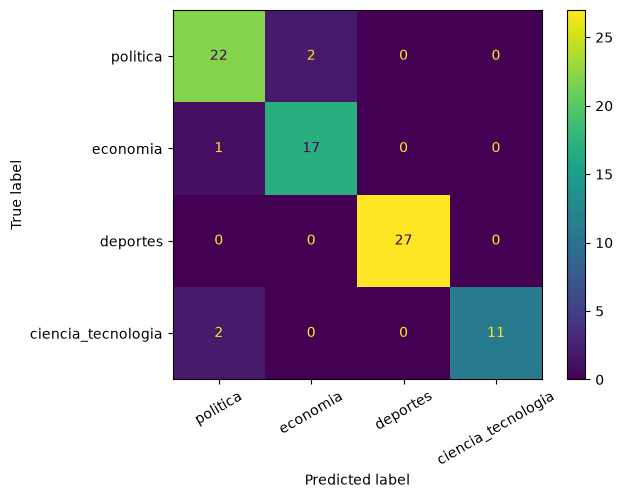

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

# Aquí se usa la prueba por primera y única vez
pred = trainer.predict(ds_prueba).predictions.argmax(axis=1)
pred_ft = [etiquetas[i] for i in pred]

f1_ft = f1_score(prueba["etiqueta_llm"], pred_ft, average="macro")
print("F1 macro, BETO ajustado:", round(f1_ft, 3), "| zero-shot:", round(f1_zero, 3))
print(classification_report(prueba["etiqueta_llm"], pred_ft, zero_division=0))

ConfusionMatrixDisplay.from_predictions(prueba["etiqueta_llm"], pred_ft,
                                        labels=etiquetas, xticks_rotation=30)

with open("datos/metricas.json", "w", encoding="utf-8") as f:
    json.dump({"f1_macro_finetuning": round(f1_ft, 4),
               "f1_macro_zero_shot": round(f1_zero, 4),
               "n_entrenamiento": len(entrenamiento),
               "n_validacion": len(validacion),
               "n_prueba": len(prueba)}, f)

## Qué hicimos

| Paso | Código | Resultado a reportar |
|---|---|---|
| Prompt con lista cerrada | `system=instrucciones` | |
| Limpiar la respuesta | `normalizar`, `categorias_validas` | |
| Etiquetar sin repetir | `isin`, `etiquetas_llm.csv` | |
| Comparar con la sección | `merge`, `crosstab` | coincidencia: ver sección 5 |
| Validación humana | `muestra_revision.csv` | acuerdo: ver sección 6 (20/20 y 14/20 en dos muestras) |
| Zero-shot | | F1 macro: ver secciones 8 y 10 |
| Fine-tuning | | F1 macro: ver secciones 8 y 10 |